# Bloc 4 — « Decision : defend the solution, not only the score »

Ce notebook **lit et présente** les sorties des phases du bloc 4 (générées par
`src/` via `make decision-bloc4`). Il ne recalcule rien : toute la logique vit
dans `src/`. Pipeline **déployé** : Random Forest calibrée ; **benchmark** :
règle métier `Fault × BasePolicy` ; **challenger** : réseau de neurones.

Discipline : choix pré-enregistrés sur 1994-95 / OOF 1995 (voir
[`reports/bloc4_decisions.md`](../reports/bloc4_decisions.md)) ; 1996 lu une
seule fois pour rapporter, avec IC bootstrap.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, str(Path.cwd().parent / "src"))
import bloc4

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

cfg = bloc4.load_config()
RES = bloc4.path(cfg, "results_dir")
FIG = bloc4.path(cfg, "figures_dir")
def table(name): return pd.read_csv(RES / name)
def show(name): display(Image(filename=str(FIG / name)))
print("Sorties lues depuis", RES.relative_to(bloc4.PROJECT_ROOT))

Sorties lues depuis reports/bloc4/results


/Users/spira/Desktop/Master/Cours/Applied ML/Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Phase 1 — Calibration (choix sur OOF 1995, rapport sur 1996)

,method,cv_brier_1995,chosen
0,none,0.0562,False
1,platt,0.0533,False
2,isotonic,0.0519,True


,method,metric,point,ci_low,ci_high
0,none,brier,0.0496,0.0481,0.0510
1,none,log_loss,0.2171,0.1898,0.2500
2,none,ece,0.0374,0.0309,0.0439
3,platt,brier,0.0475,0.0463,0.0485
4,platt,log_loss,0.1933,0.1890,0.1970
5,platt,ece,0.0376,0.0324,0.0440
6,isotonic,brier,0.0461,0.0448,0.0470
7,isotonic,log_loss,0.1771,0.1720,0.1818
8,isotonic,ece,0.0059,0.0049,0.0120


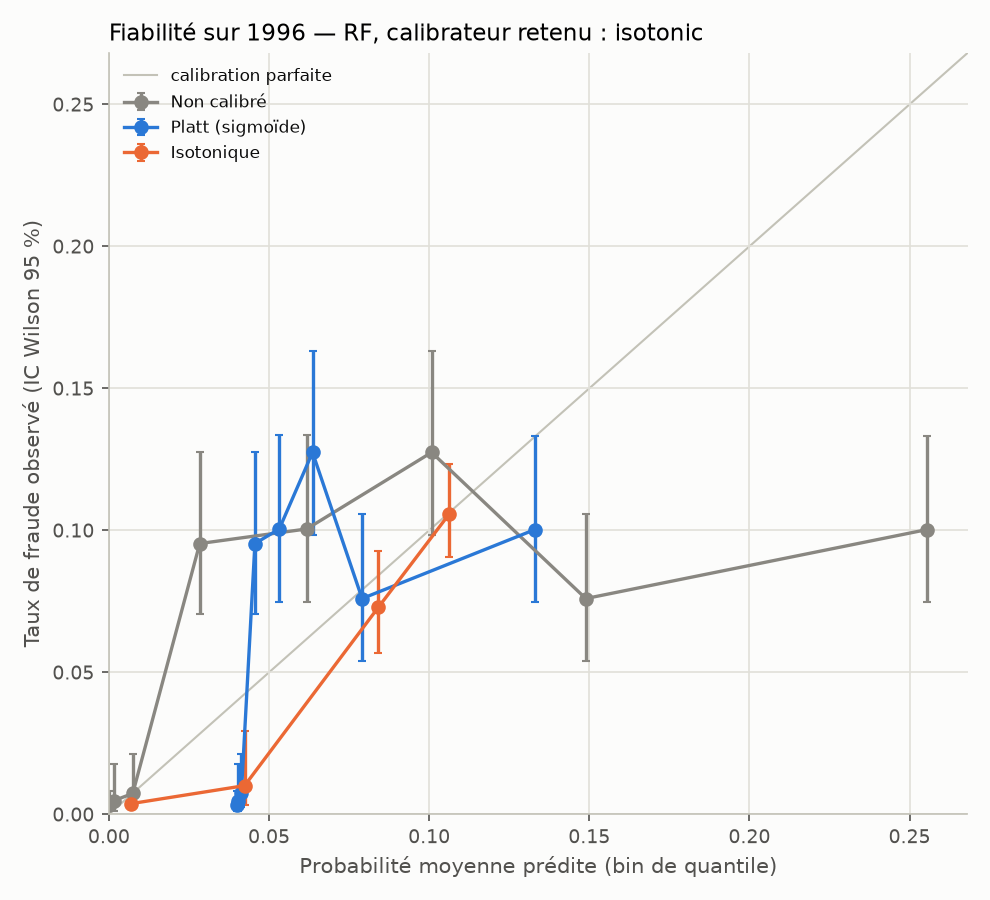

In [2]:
display(table("calibration_selection.csv"))
display(table("calibration_metrics.csv"))
show("calibration_reliability.png")

## Phase 2 — Seuil opérationnel et comparaison des décisions

Seuil de budget appliqué à 1996 :


,metric,point,ci_low,ci_high
0,recall,0.1831,0.1315,0.2347
1,precision,0.0992,0.0734,0.1279
2,f2,0.1566,0.1146,0.2016
3,flagged_frac,0.0963,0.0869,0.1046


Analyse de coût (seuil cherché sur 1995) :


,ratio,threshold,cost,flagged_frac,fn,fp,bayes_threshold,holdout_flagged_frac,holdout_recall,is_primary
0,5,0.2000,"1,465.0000",0.0027,292,5,0.1667,0.0022,0.0329,False
1,10,0.1003,"2,716.0000",0.3245,121,1506,0.0909,0.3355,0.6808,True
2,20,0.0841,"3,161.0000",0.5168,37,2421,0.0476,0.5339,0.9577,False
3,50,0.0246,"3,632.0000",0.6393,12,3032,0.0196,0.6241,0.9718,False


Décisions au même budget (10 % de 1996) :


,model,n_flagged,tp,fp,fn,recall,precision,f2,flagged_frac
0,rf__fs_basepolicy,409,41,368,172,0.1925,0.1002,0.1626,0.1002
1,business,409,50,359,163,0.2347,0.1222,0.1983,0.1002
2,mlp__fs_basepolicy,409,42,367,171,0.1972,0.1027,0.1665,0.1002


,model_a,model_b,a_only_frauds,b_only_frauds,discordant,mcnemar_p,jaccard_flagged
0,rf__fs_basepolicy,business,20,29,49,0.2529,0.2546
1,rf__fs_basepolicy,mlp__fs_basepolicy,16,17,33,1.0000,0.4226
2,business,mlp__fs_basepolicy,29,21,50,0.3222,0.3046


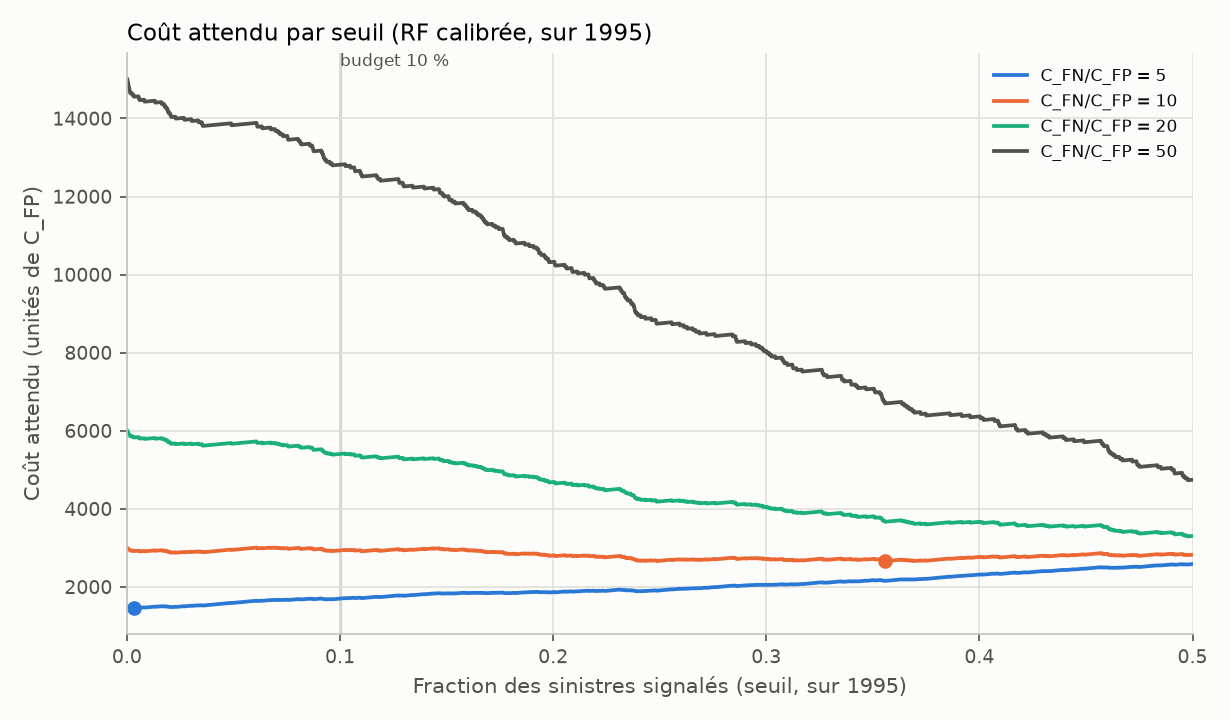

In [3]:
print("Seuil de budget appliqué à 1996 :")
display(table("threshold_operating.csv"))
print("Analyse de coût (seuil cherché sur 1995) :")
display(table("threshold_cost.csv"))
print("Décisions au même budget (10 % de 1996) :")
display(table("threshold_decisions.csv"))
display(table("threshold_mcnemar.csv"))
show("threshold_cost.png")

## Phase 2bis — Pourquoi la règle métier tient

,cell,n,n_fraud,fraud_rate,rate_lo,rate_hi,share_claims,share_frauds
0,Policy Holder | Collision,1117,124,0.1110,0.0939,0.1308,0.2736,0.5822
1,Policy Holder | All Perils,695,72,0.1036,0.0831,0.1285,0.1702,0.3380
2,Policy Holder | Liability,1135,10,0.0088,0.0048,0.0161,0.2780,0.0469
3,Third Party | All Perils,438,4,0.0091,0.0036,0.0232,0.1073,0.0188
4,Third Party | Collision,510,3,0.0059,0.0020,0.0172,0.1249,0.0141


Gain intra-case (case focus) :


,cell,n,n_fraud,prevalence,model,pr_auc,pr_auc_lo,pr_auc_hi,beats_chance
0,Policy Holder | All Perils,695,72,0.1036,rf__fs_basepolicy,0.1100,0.0928,0.1457,False
1,Policy Holder | All Perils,695,72,0.1036,mlp__fs_basepolicy,0.1148,0.0880,0.1650,False
2,Policy Holder | All Perils,695,72,0.1036,svm__fs_basepolicy,0.1193,0.0995,0.1623,False


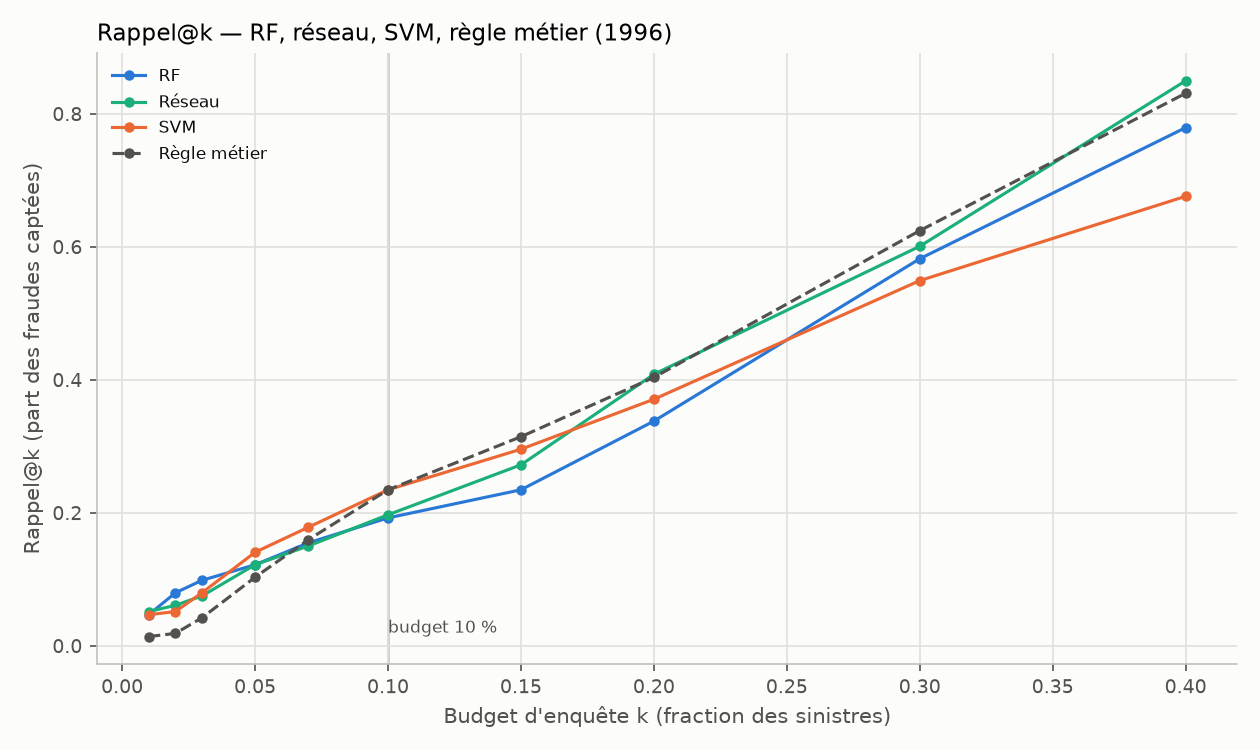

# Pourquoi la règle métier tient face aux modèles au budget d'enquête

Diagnostic descriptif des modèles **existants** (RF déployée, réseau challenger, SVM), sans aucune amélioration. Généré par `src/diagnostic.py` ; tous les chiffres sont calculés. Lecture sur 1996, confirmée par les OOF 1995.

## 1. Le signal est concentré dans quelques cases Fault × BasePolicy
- Les 2 cases les plus chargées — Policy Holder | Collision et Policy Holder | All Perils — représentent 44.4% des sinistres et **92.0% des fraudes** de 1996 (1995 : 92.0%). -> La règle métier exploite directement cette structure.
  - Policy Holder | Collision : 1117 sinistres, taux 11.1% [9.4%, 13.1%], 58.2% des fraudes.
  - Policy Holder | All Perils : 695 sinistres, taux 10.4% [8.3%, 12.8%], 33.8% des fraudes.
  - Policy Holder | Liability : 1135 sinistres, taux 0.9% [0.5%, 1.6%], 4.7% des fraudes.
  - Third Party | All Perils : 438 sinistres, taux 0.9% [0.4%, 2.3%], 1.9% des fraudes.

## 2. Gain intra-case : trier DANS « Policy Holder | All Perils »
- Dans « Policy Holder | All Perils » (prévalence 10.4%, 72 fraudes), PR-AUC sur 1996 :
  - RF : 0.110 [0.093, 0.146] = hasard (IC couvre la prévalence).
  - Réseau : 0.115 [0.088, 0.165] = hasard (IC couvre la prévalence).
  - SVM : 0.119 [0.099, 0.162] = hasard (IC couvre la prévalence).
- Confirmation 1995 : RF 0.100, Réseau 0.120, SVM 0.134.
- **Conséquence** : aucun modèle ne trie significativement mieux que le hasard dans la case -> l'essentiel du pouvoir discriminant vient du CHOIX de la case, que la règle métier capture déjà.

## 3. À quel budget les modèles dépassent-ils la règle ?
- RF mène sur la règle jusqu'à k ≈ 5.0%, mais au budget de 10 % il ne mène pas : rappel 19.2% vs règle 23.5%.
- Réseau mène sur la règle jusqu'à k ≈ 5.0%, mais au budget de 10 % il ne mène pas : rappel 19.7% vs règle 23.5%.
- SVM mène sur la règle jusqu'à k ≈ 7.0%, mais au budget de 10 % il ne mène pas : rappel 23.5% vs règle 23.5%.
- **Conséquence** : les modèles ne gagnent qu'aux **tout petits budgets** (la règle métier ne sait pas classer DANS une case) ; dès 10 %, la règle reprend l'avantage. Le budget d'enquête tombe dans la zone où la règle est forte.

## 4. Composition du top 10 % (1996)
- RF : Policy Holder | All Perils 69.7%, Policy Holder | Collision 28.1%.
- Réseau : Policy Holder | All Perils 80.7%, Policy Holder | Collision 15.4%.
- SVM : Policy Holder | All Perils 45.2%, Policy Holder | Collision 36.2%.
- Règle métier : Policy Holder | All Perils 100.0%.

## 5. Instabilité temporelle
- Taux de fraude annuel : 1994 6.7%, 1995 5.8%, 1996 5.2%.
  - RF : PR-AUC CV 0.148 ± 0.068 entre folds.
  - Réseau : PR-AUC CV 0.154 ± 0.047 entre folds.
  - SVM : PR-AUC CV 0.140 ± 0.065 entre folds.
- **Conséquence** : la variance inter-fold est du même ordre que les écarts entre modèles -> prudence sur tout classement fin.

## 6. SHAP de la RF dans « Policy Holder | All Perils » (1996)
- Variables qui **trient le plus À L'INTÉRIEUR** de la case (écart-type du SHAP ; Fault et BasePolicy y sont constantes, donc ne trient pas) :
  - Age : écart-type SHAP 0.0140 (|SHAP| moyen 0.0116)
  - AccidentArea : écart-type SHAP 0.0137 (|SHAP| moyen 0.0076)
  - Month : écart-type SHAP 0.0118 (|SHAP| moyen 0.0095)
  - Make : écart-type SHAP 0.0116 (|SHAP| moyen 0.0068)
  - MonthClaimed : écart-type SHAP 0.0115 (|SHAP| moyen 0.0090)
  - AddressChange-Claim : écart-type SHAP 0.0106 (|SHAP| moyen 0.0038)
- **Conséquence** : même les variables les plus discriminantes DANS la case ont un effet faible -> cohérent avec le §2 (pas de tri utile intra-case).
- SHAP explique le MODÈLE, pas la causalité de la fraude.

## 7. Option hybride (règle filtre, RF classe)
- Gain intra-case non significatif -> option hybride non évaluée (elle n'apporterait rien de démontrable).

## Ce qu'on peut affirmer / ne pas affirmer
**On peut affirmer :**
- Le signal est concentré : 2 cases = 92.0% des fraudes.
- La règle métier capture cette concentration et, au budget de 10 %, n'est pas battue de façon démontrable par la RF (Phase 2, McNemar non significatif).
**On ne peut PAS affirmer :**
- Que la RF est inutile : son avantage existe peut-être à budget plus large ou en probabilité calibrée (Phase 1).
- Que ces variables *causent* la fraude : SHAP explique le modèle, pas la causalité.

## Réponse de 3 phrases pour le jury
> Sur ces données, 92 % des fraudes tiennent dans deux cases Fault × BasePolicy, et la règle métier exploite directement cette concentration. Au budget d'enquête de 10 %, trier plus finement À L'INTÉRIEUR des cases n'apporte pas de gain démontrable : la RF ne bat pas la règle métier de façon significative (McNemar non significatif). La RF reste utile pour fournir des probabilités calibrées et, éventuellement, un tri complémentaire au-delà du budget — mais la décision par défaut raisonnable au budget de 10 % reste la règle métier.



In [4]:
display(table("diagnostic_concentration_holdout.csv").head(5))
print("Gain intra-case (case focus) :")
ic = table("diagnostic_intra_case_holdout.csv")
display(ic[ic["cell"] == cfg["diagnostic"]["focus_cell"]])
show("diagnostic_recall_curve_holdout.png")
display(Markdown((bloc4.path(cfg, "why_baseline")).read_text()))

## Phase 3 — Weak slices et équité (1996, au seuil)

Slices signalées (IC de rappel entièrement sous le global) :


,segment,level,n,n_fraud,n_flagged,tp,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,interpretable,weak_recall
7,AgeOfPolicyHolder,41 to 50,766,36,43,2,0.0556,0.0154,0.1814,0.0465,0.0128,0.1546,True,True
21,BasePolicy,Collision,1627,127,110,6,0.0472,0.0218,0.0992,0.0545,0.0252,0.1139,True,True


Calibration par slice (équité) :


,segment,level,n,obs_rate,obs_lo,obs_hi,mean_pred,gap,interpretable
0,Sex,Female,629,0.0413,0.0284,0.0599,0.0528,0.0115,True
1,Sex,Male,3454,0.0541,0.0471,0.0622,0.0591,0.0049,True
2,AgeOfPolicyHolder,16 to 17,70,0.0143,0.0025,0.0766,0.0824,0.0681,True
3,AgeOfPolicyHolder,21 to 25,24,0.1250,0.0434,0.3100,0.0794,-0.0456,False
4,AgeOfPolicyHolder,26 to 30,145,0.0759,0.0429,0.1307,0.0650,-0.0109,True
5,AgeOfPolicyHolder,31 to 35,1493,0.0516,0.0415,0.0640,0.0559,0.0044,True
6,AgeOfPolicyHolder,36 to 40,1070,0.0589,0.0463,0.0746,0.0583,-0.0006,True
7,AgeOfPolicyHolder,41 to 50,766,0.0470,0.0341,0.0644,0.0559,0.0089,True
8,AgeOfPolicyHolder,51 to 65,366,0.0492,0.0313,0.0764,0.0585,0.0093,True
9,AgeOfPolicyHolder,over 65,149,0.0268,0.0105,0.0670,0.0672,0.0403,True


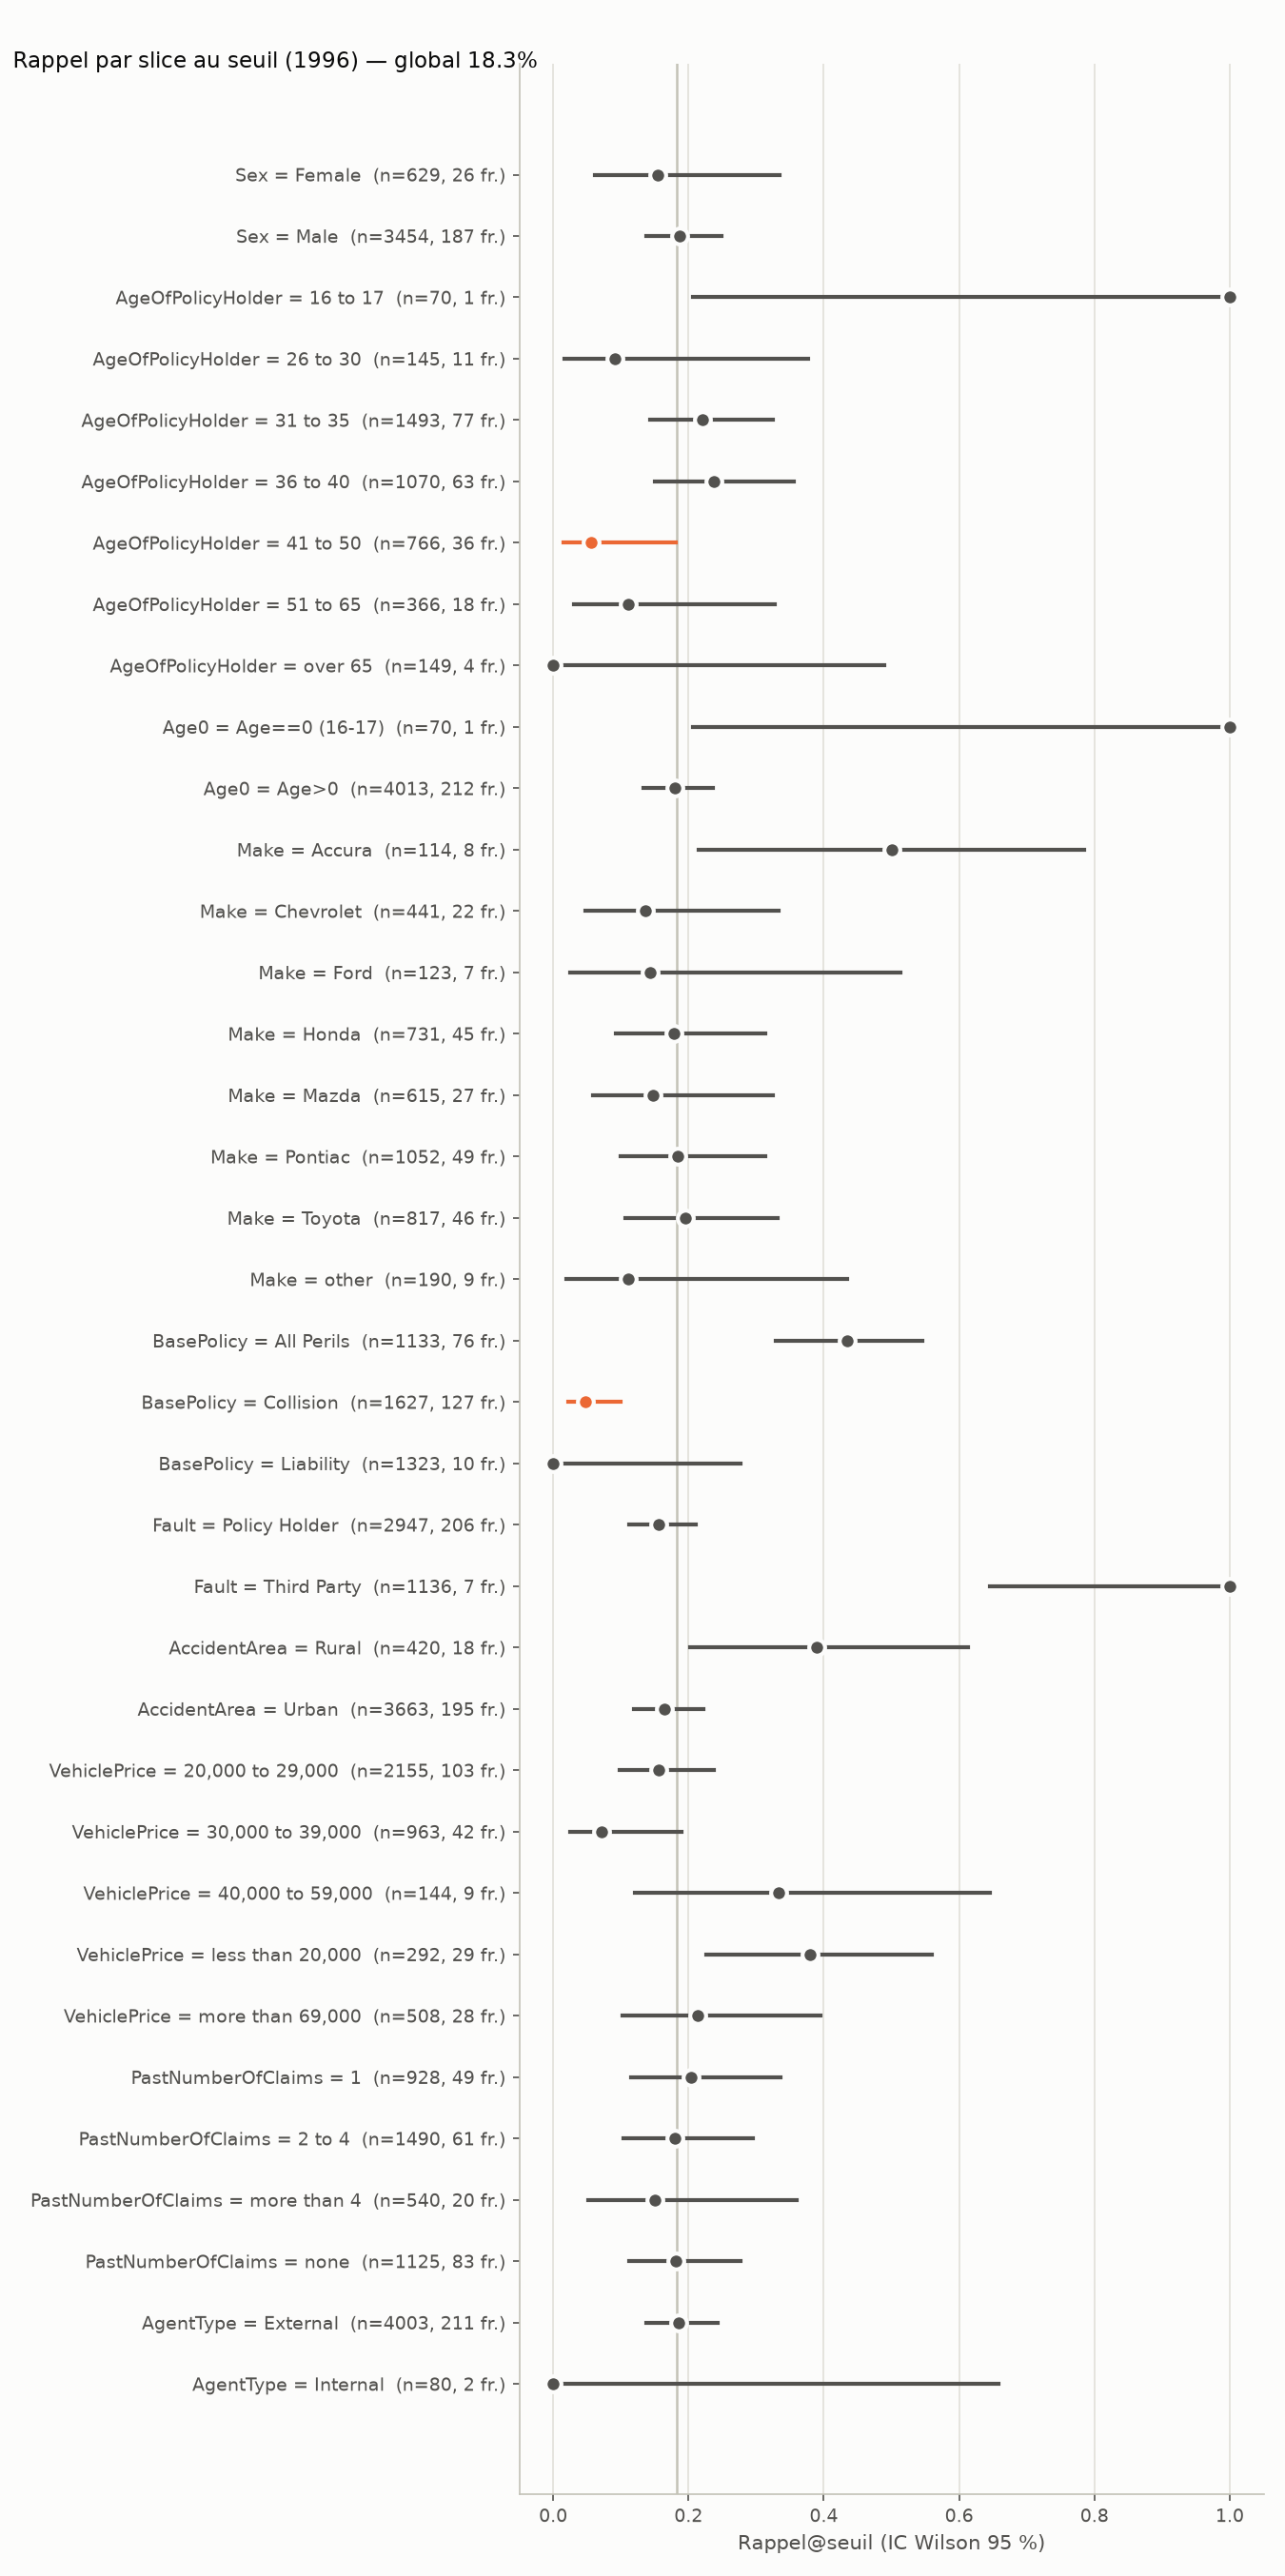

In [5]:
sl = table("slices_recall_precision.csv")
print("Slices signalées (IC de rappel entièrement sous le global) :")
display(sl[sl["weak_recall"]])
print("Calibration par slice (équité) :")
display(table("slices_fairness_calibration.csv"))
show("slices_recall.png")

## Phase 4 — Explications SHAP (modèle déployé)

,variable,mean_abs_shap,std_shap
0,BasePolicy,0.0414,0.0523
1,Fault,0.0357,0.0433
2,Month,0.0080,0.0106
3,MonthClaimed,0.0055,0.0080
4,Age,0.0055,0.0094
5,RepNumber,0.0048,0.0068
6,DayOfWeek,0.0048,0.0067
7,VehiclePrice,0.0046,0.0076
8,AccidentArea,0.0046,0.0095
9,AddressChange-Claim,0.0043,0.0132


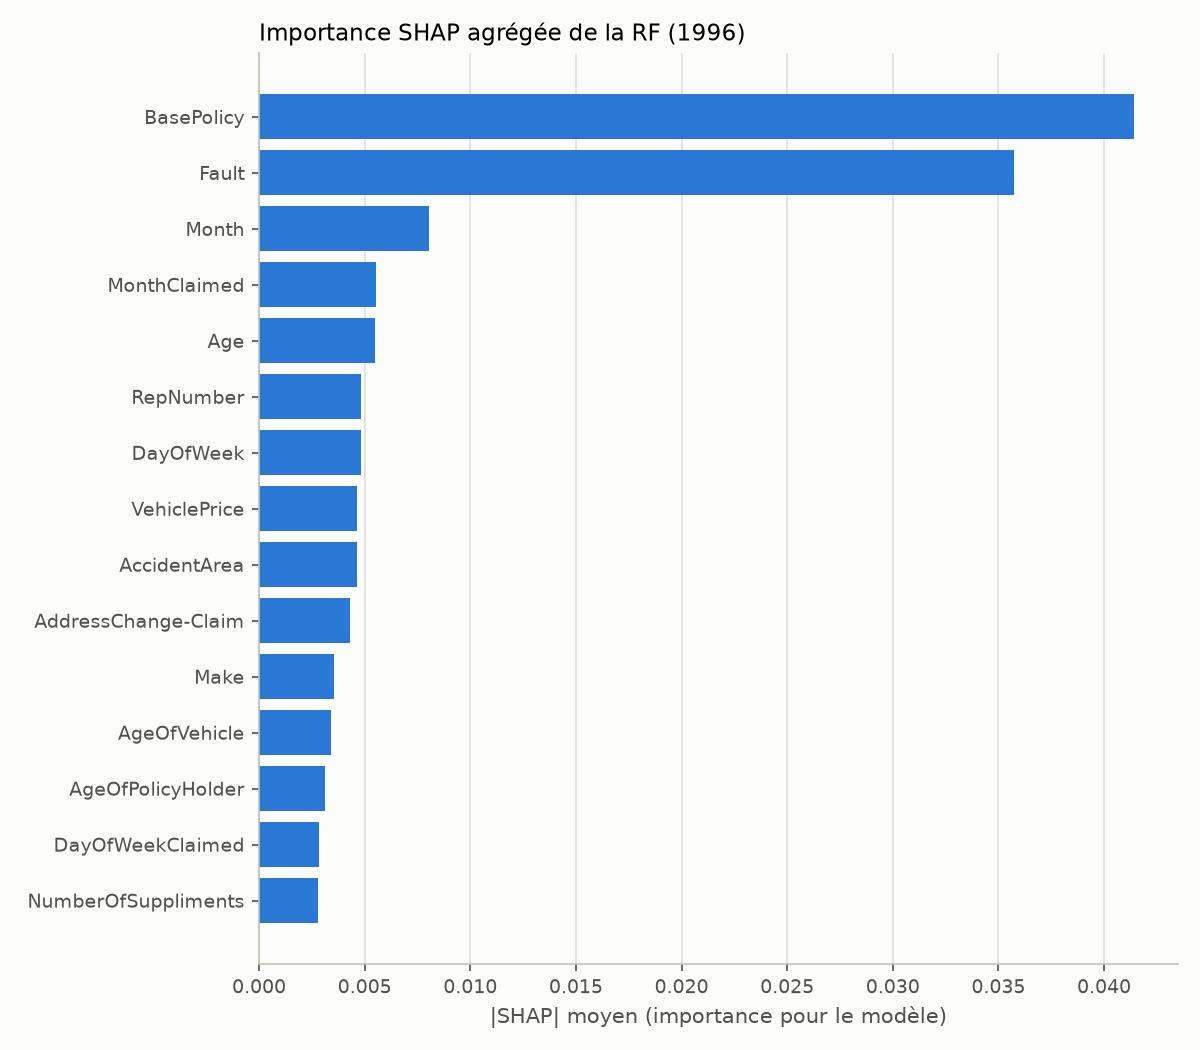

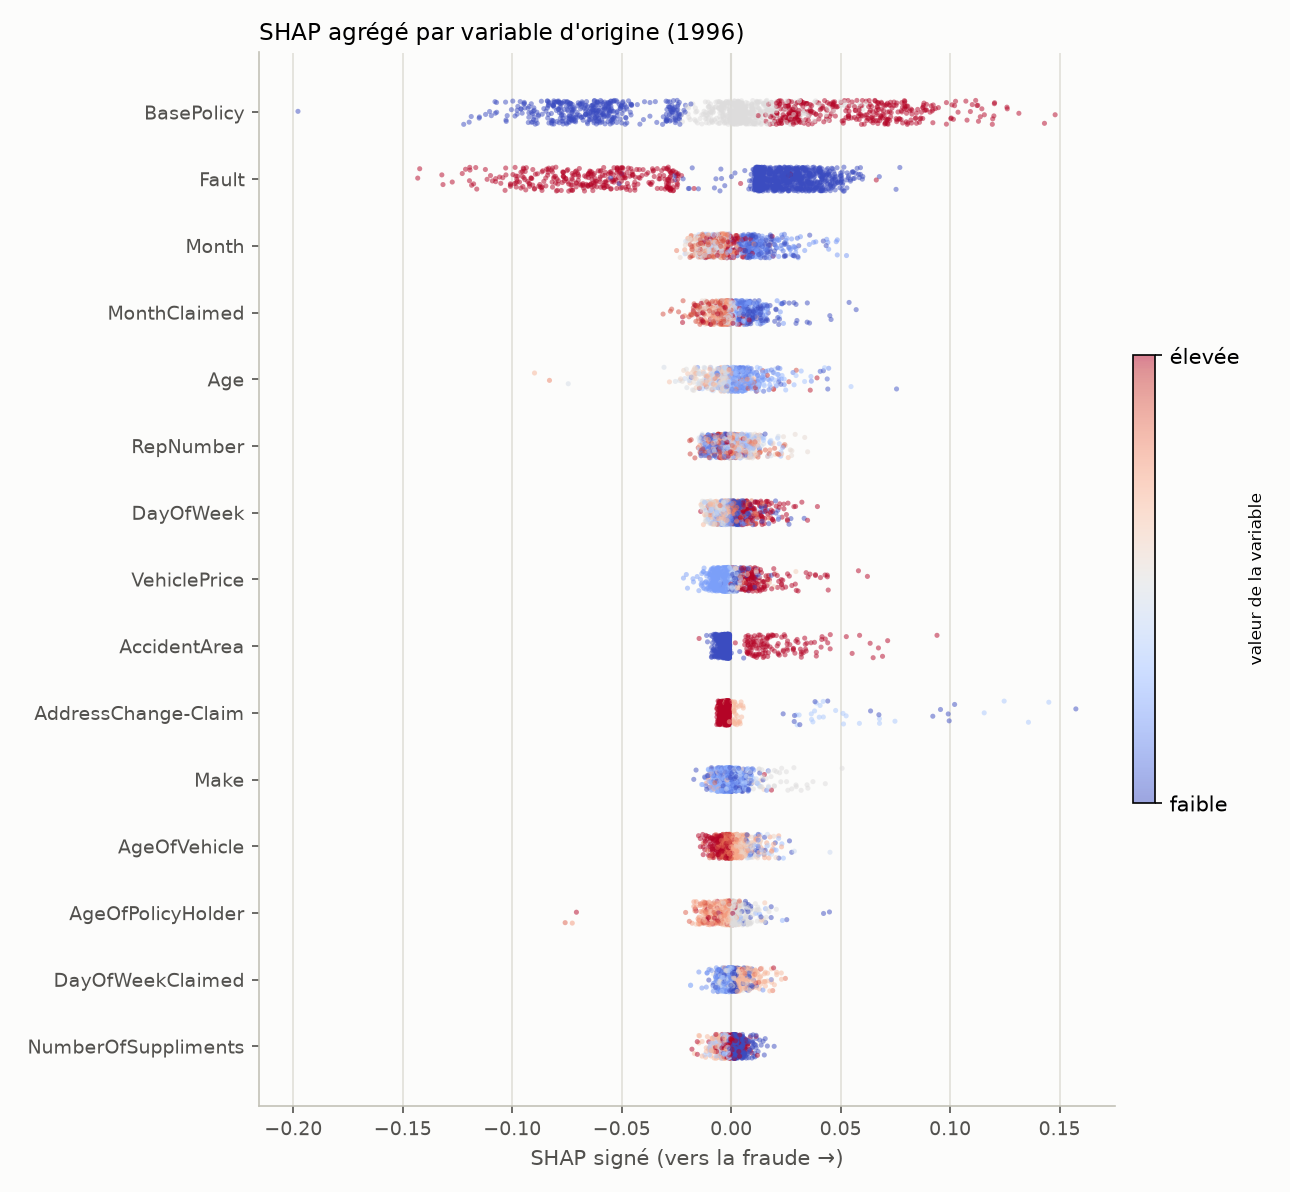

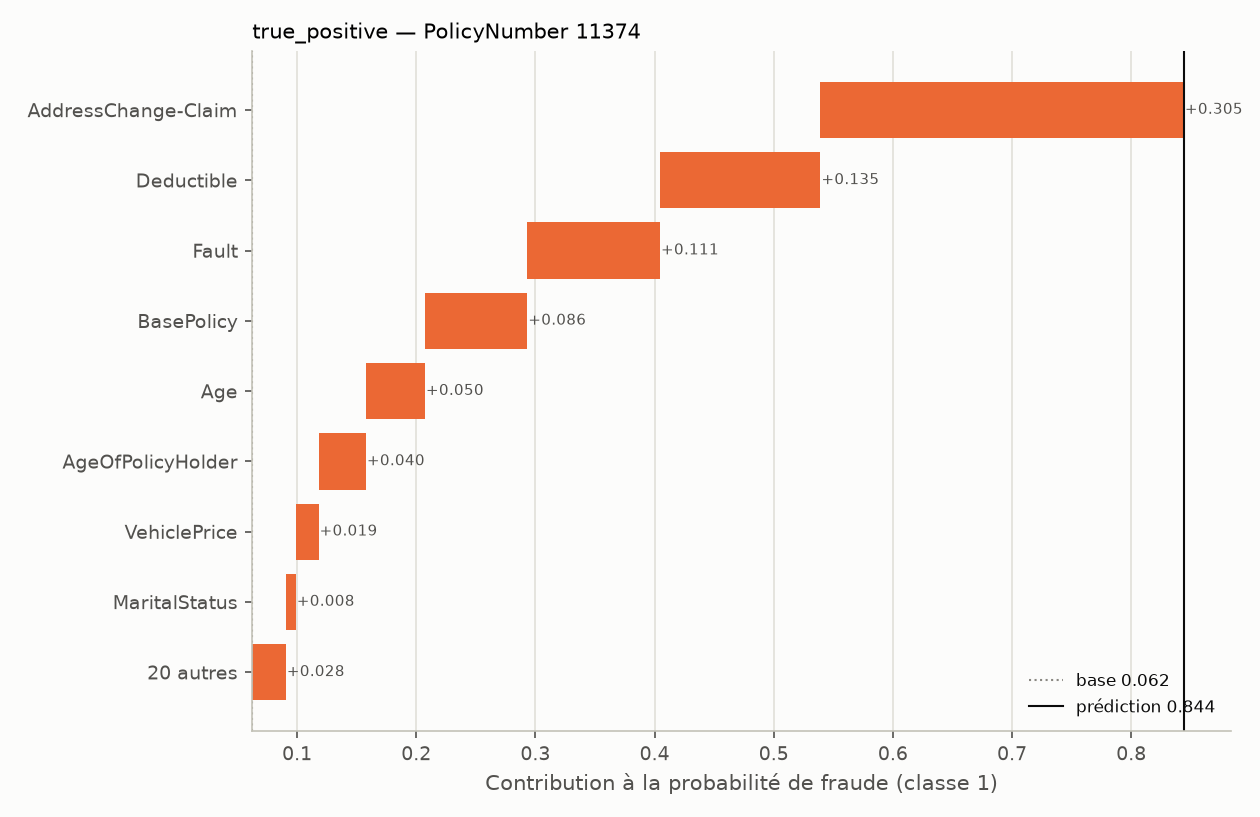

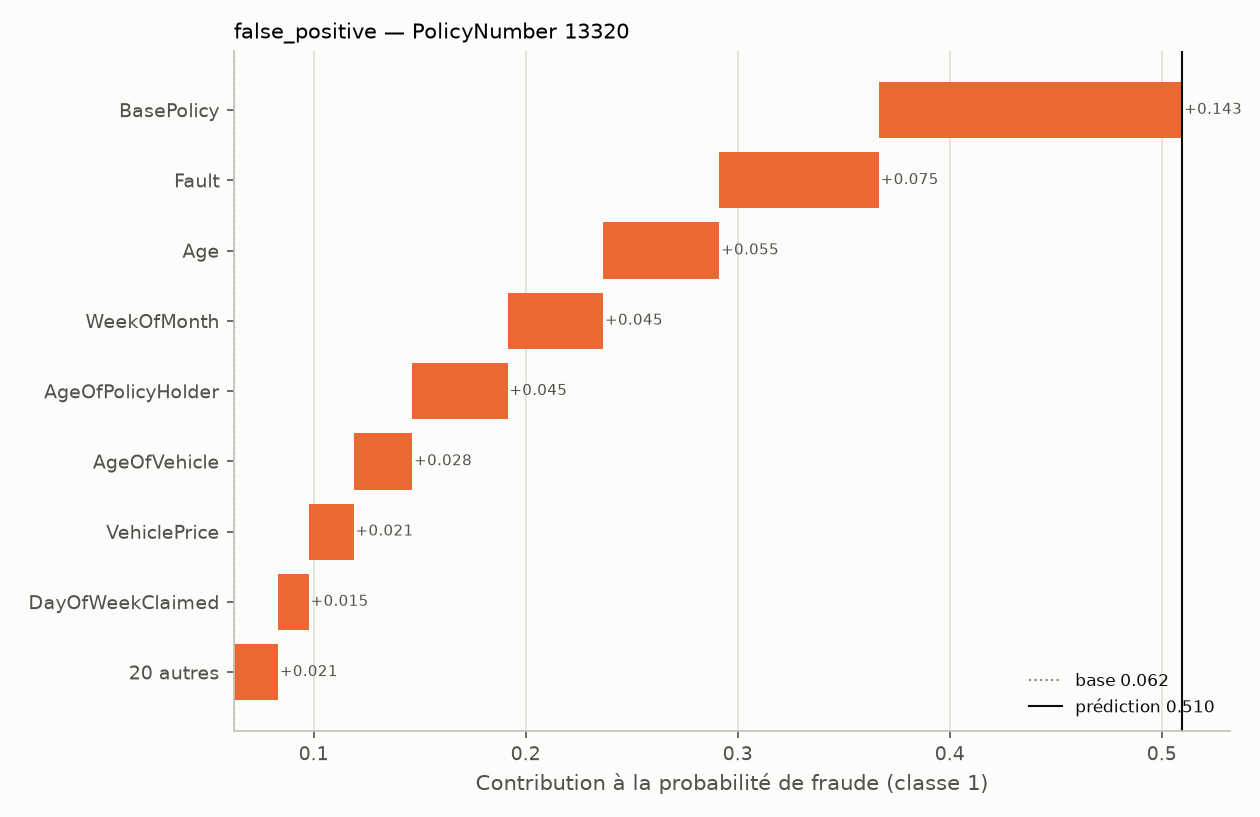

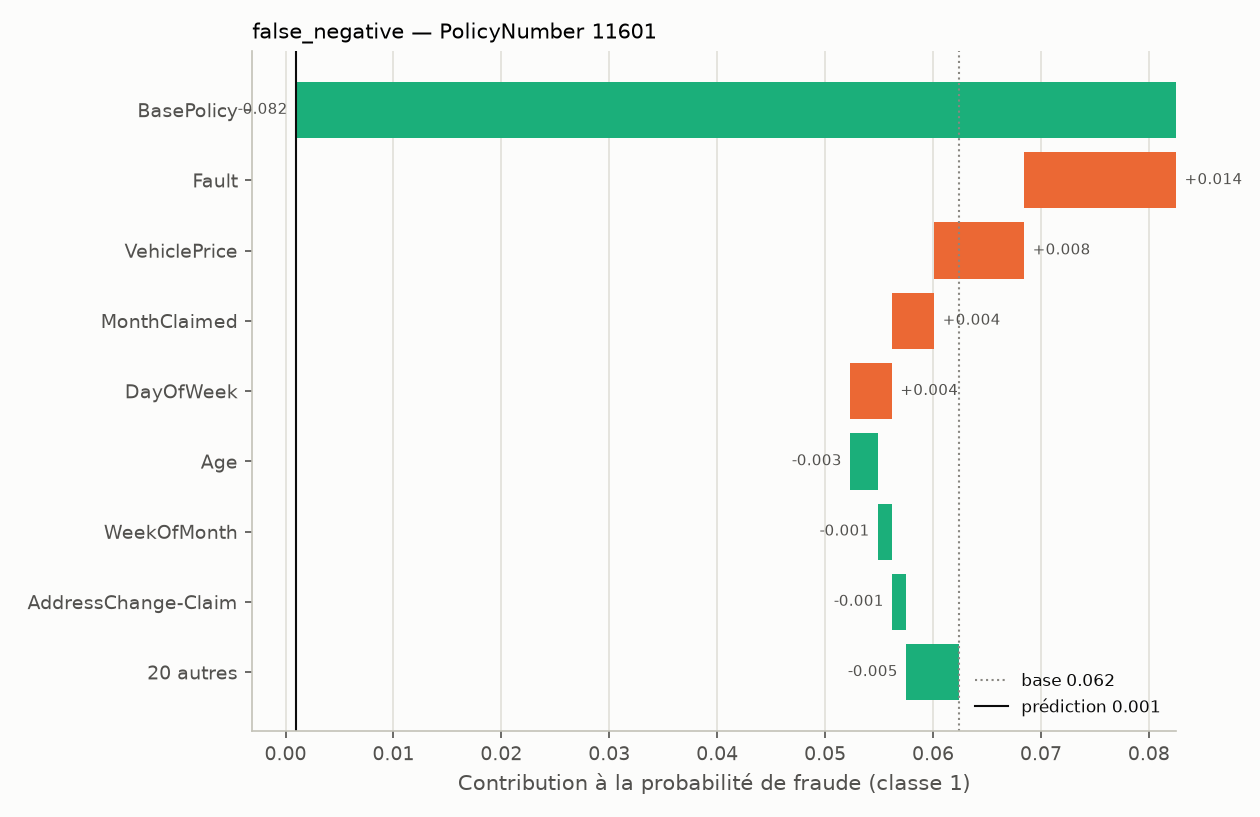

• Vrai positif (fraude signalée) — case Third Party × Collision, probabilité calibrée 100.0%. Poids décisifs : AddressChange-Claim (+0.305), Deductible (+0.135). SHAP explique le modèle, pas la cause.
• Faux positif (sinistre sain signalé) — case Policy Holder × All Perils, probabilité calibrée 20.0%. Poids décisifs : BasePolicy (+0.143), Fault (+0.075). SHAP explique le modèle, pas la cause.
• Faux négatif (fraude manquée) — case Policy Holder × Liability, probabilité calibrée 0.5%. Poids décisifs : BasePolicy (-0.082), Fault (+0.014). SHAP explique le modèle, pas la cause.


In [6]:
display(table("shap_global_importance.csv").head(12))
show("shap_global_bar.png")
show("shap_global_beeswarm.png")
for kind in ("true_positive", "false_positive", "false_negative"):
    show(f"shap_local_{kind}.png")
cases = json.loads((RES / "shap_local_cases.json").read_text())
for c in cases.values():
    print("•", c["sentence"])

## Décision finale et limites

In [7]:
display(Markdown((bloc4.path(cfg, "report")).read_text()))

# Bloc 4 « Decision » — rapport de décision

Généré par `src/report_bloc4.py` à partir des sorties des phases ; tous les chiffres sont calculés. Pipeline **déployé** : Random Forest calibrée (`rf__fs_basepolicy`) ; **benchmark** : règle métier Fault × BasePolicy ; **challenger** : réseau de neurones. 1996 n'est lu que pour rapporter.

## 1. Calibration
- Calibrateur retenu (CV interne 1995) : **isotonic**.
- Sur 1996 : Brier 0.0461 vs brut 0.0496 vs baseline prior 0.0496 ; ECE 0.0059 vs brut 0.0374.
- **Conséquence** : le score brut de la RF n'est qu'un rang (même Brier que le prior) ; la calibration isotonic le rend exploitable comme probabilité (ECE divisé par ~6).

## 2. Seuil opérationnel
- Budget 10.0% (rang brut), seuil dérivé de 1995 appliqué à 1996 : 393 enquêtes (9.6%), rappel 18.3%, précision 9.9%, F2 0.157.
- Coût (ratio principal C_FN/C_FP = 10) : l'optimum coût signale 32.5% des sinistres — très au-dessus du budget de 10.0% -> le budget est une contrainte de **capacité**, pas l'optimum de coût.

## 3. Décisions comparées au même budget (10 %)
- RF : rappel 19.2%, précision 10.0% (41 fraudes / 409).
- Règle métier : rappel 23.5%, précision 12.2% (50 fraudes).
- RF vs règle : Jaccard 0.25, McNemar p = 0.253 -> **gain de la RF non démontré** au budget de 10 % ; décisions complémentaires (fraudes propres 20 RF / 29 règle).

## 4. Pourquoi la règle métier tient (diagnostic)
- 2 cases Fault × BasePolicy = 44.4% des sinistres et **92.0% des fraudes**.
- Aucun modèle ne trie mieux que le hasard DANS la plus grande case (cf. `reports/bloc4_why_baseline.md`). Détail et réponse jury : ce fichier.

## 5. Weak slices et équité
- Slices sous-servies (IC de rappel entièrement sous le global 18.3%) : AgeOfPolicyHolder=41 to 50, BasePolicy=Collision -> la RF concentre ses alertes sur « All Perils » et sous-sert « Collision ».
- Ablation sans Sex : écart PR-AUC +0.0012 (Sex quasi inutile). Détail équité : `reports/bloc4/results/slices_fairness_calibration.csv`.

## 6. Explications SHAP
- Importance globale (|SHAP| moyen) : BasePolicy 0.041, Fault 0.036, Month 0.008, MonthClaimed 0.006, Age 0.005.
- Fault + BasePolicy portent **50.8%** de l'importance -> la RF s'appuie sur la même structure que la règle métier.
  - Vrai positif (fraude signalée) — case Third Party × Collision, probabilité calibrée 100.0%. Poids décisifs : AddressChange-Claim (+0.305), Deductible (+0.135). SHAP explique le modèle, pas la cause.
  - Faux positif (sinistre sain signalé) — case Policy Holder × All Perils, probabilité calibrée 20.0%. Poids décisifs : BasePolicy (+0.143), Fault (+0.075). SHAP explique le modèle, pas la cause.
  - Faux négatif (fraude manquée) — case Policy Holder × Liability, probabilité calibrée 0.5%. Poids décisifs : BasePolicy (-0.082), Fault (+0.014). SHAP explique le modèle, pas la cause.

## 7. Recommandation finale
- **Déployer la RF calibrée (isotonic)** pour fournir des probabilités de fraude fiables, conformément à la décision d'équipe (règle v2).
- **Mais** au budget d'enquête de 10 %, la règle métier reste au moins aussi bonne (rappel 23.5% ≥ 19.2%) et le gain de la RF n'est pas démontré : présenter la RF **et** la règle métier au comité, la RF apportant le tri fin aux petits budgets et la probabilité calibrée.
- **Auditer en priorité** la slice BasePolicy=Collision (sous-servie) et surveiller la calibration par âge (sur-prédiction 16-17 et >65).

## 8. Limites
- **Holdout non vierge** : 1996 a déjà servi aux blocs 2 ; ces chiffres sont une confirmation, pas une estimation non biaisée.
- **Dérive** : les IC bootstrap ne couvrent que l'échantillonnage de 1996, ni le réentraînement ni la dérive au-delà de 1996.
- **Petits effectifs par slice** : plusieurs modalités ont n < 30 (non concluant).
- **SHAP explique le modèle, pas la causalité** de la fraude.
- **Plan de monitoring** : suivre mensuellement le taux de fraude par case Fault × BasePolicy, la calibration (ECE) et le rappel par slice ; réentraîner si l'ECE ou le rappel@budget se dégradent au-delà des IC de 1996.

